In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [6]:
url = "https://raw.githubusercontent.com/aksp42/unemployment-india-analysis/main/Unemployment%20in%20India.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

print(df.head())

Dataset Loaded Successfully
           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                                     43.97  Rural  
4           12256762.0                                     44.68  Rural  


In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(768, 7)

Column Names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: 

In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate Rows:
27


In [11]:
print(df.columns.tolist())
print(df.dtypes)

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object


In [12]:
print(df.columns.tolist())

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [13]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(
    df['Date'].astype(str).str.strip(),
    dayfirst=True,
    errors='coerce'
)

# Remove missing dates
df = df.dropna(subset=['Date'])

# Remove missing unemployment rates
df = df.dropna(
    subset=['Estimated Unemployment Rate (%)']
)

print("Data Cleaning Completed Successfully")

print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Data Cleaning Completed Successfully
           Region       Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh 2019-05-31   Monthly                             3.65   
1  Andhra Pradesh 2019-06-30   Monthly                             3.05   
2  Andhra Pradesh 2019-07-31   Monthly                             3.75   
3  Andhra Pradesh 2019-08-31   Monthly                             3.32   
4  Andhra Pradesh 2019-09-30   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  
0          11999139.0                                    43.24  Rural  
1          11755881.0                                    42.05  Rural  
2          12086707.0                                    43.50  Rural  
3          12285693.0                                    43.97  Rural  
4          12256762.0                                    44.68  Rural  

Missing Values:
Region                                     0
Date              

In [14]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (740, 7)

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes:

In [15]:
print("Average Unemployment Rate:")
print(df['Estimated Unemployment Rate (%)'].mean())

Average Unemployment Rate:
11.787945945945946


In [16]:
print("Maximum Unemployment Rate:")
print(df['Estimated Unemployment Rate (%)'].max())

print("\nMinimum Unemployment Rate:")
print(df['Estimated Unemployment Rate (%)'].min())

Maximum Unemployment Rate:
76.74

Minimum Unemployment Rate:
0.0


In [17]:
region_data = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print(region_data)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


In [18]:
area_data = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

print(area_data)

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


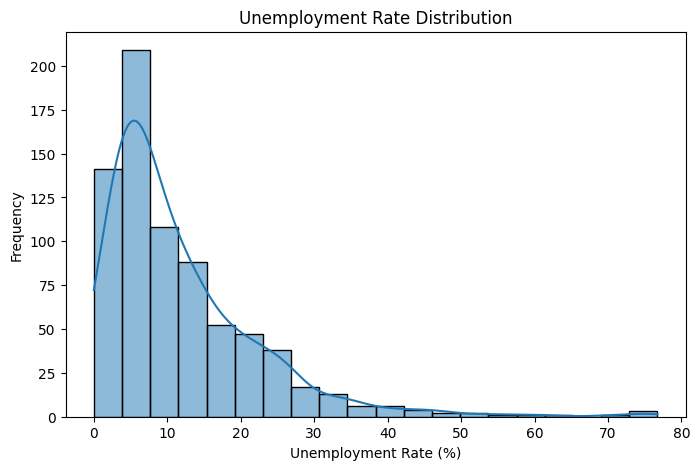

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['Estimated Unemployment Rate (%)'],
    bins=20,
    kde=True
)

plt.title("Unemployment Rate Distribution")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.show()

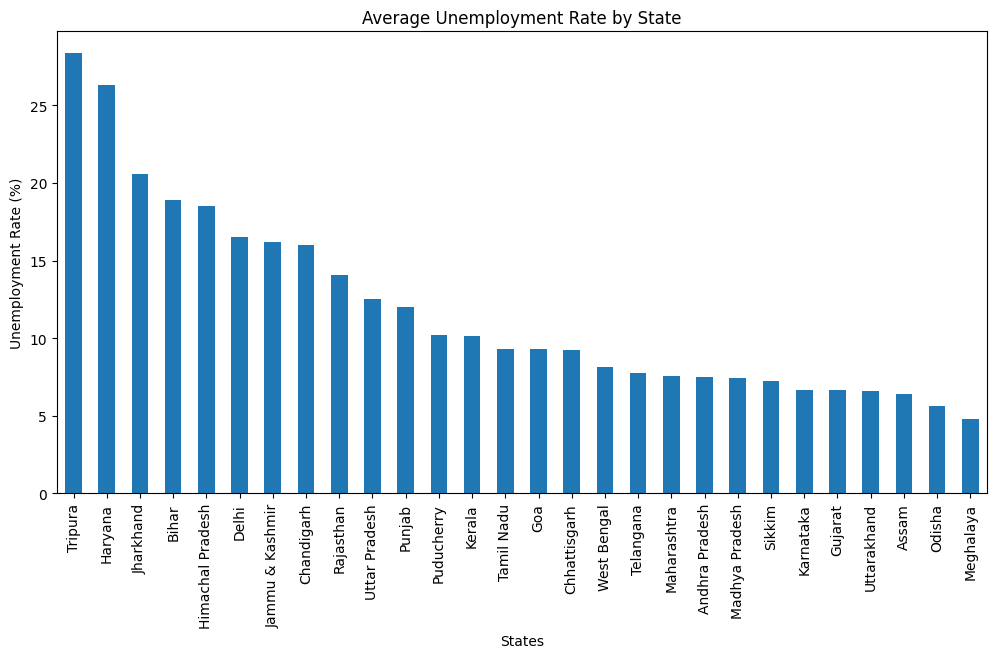

In [20]:
state_data = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))

state_data.plot(kind='bar')

plt.title("Average Unemployment Rate by State")
plt.xlabel("States")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=90)
plt.show()

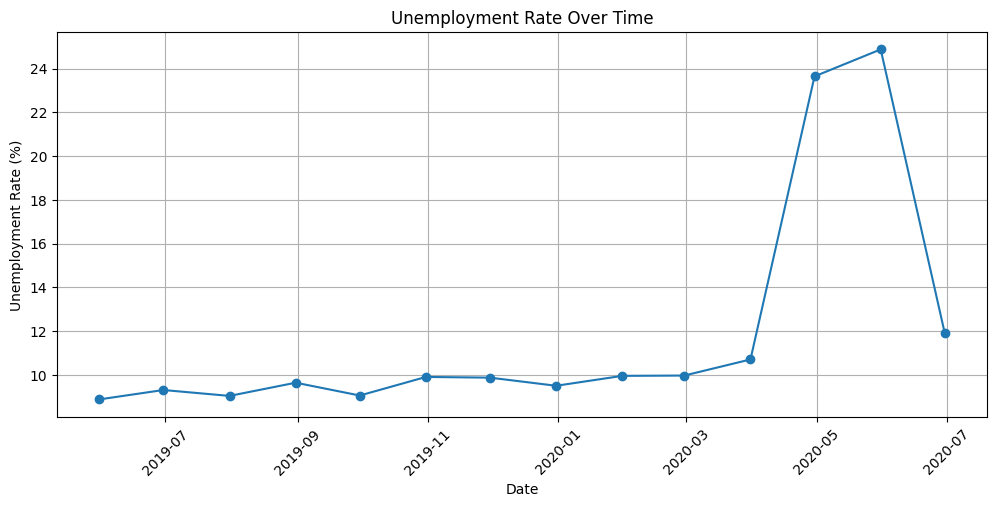

In [21]:
monthly_data = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean()

plt.figure(figsize=(12,5))

plt.plot(monthly_data.index, monthly_data.values, marker='o')

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

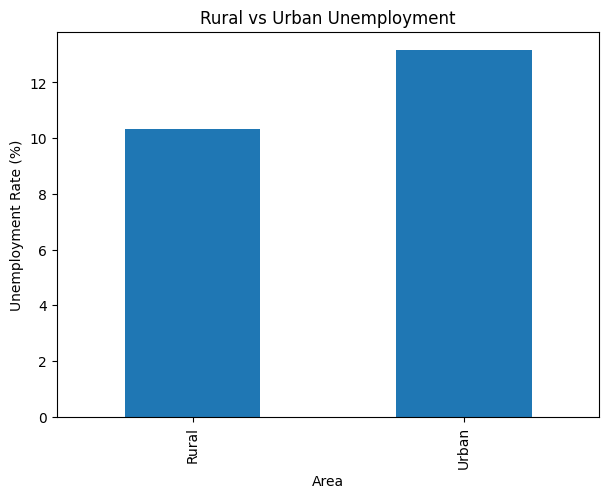

In [22]:
area_data = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

plt.figure(figsize=(7,5))

area_data.plot(kind='bar')

plt.title("Rural vs Urban Unemployment")
plt.xlabel("Area")
plt.ylabel("Unemployment Rate (%)")

plt.show()

In [23]:
df['COVID Period'] = np.where(
    df['Date'] < '2020-03-25',
    'Before COVID',
    'During COVID'
)

print(df[['Date', 'COVID Period']].head(10))

        Date  COVID Period
0 2019-05-31  Before COVID
1 2019-06-30  Before COVID
2 2019-07-31  Before COVID
3 2019-08-31  Before COVID
4 2019-09-30  Before COVID
5 2019-10-31  Before COVID
6 2019-11-30  Before COVID
7 2019-12-31  Before COVID
8 2020-01-31  Before COVID
9 2020-02-29  Before COVID


In [24]:
covid_data = df.groupby('COVID Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print("COVID-19 Impact:")
print(covid_data)

COVID-19 Impact:
COVID Period
Before COVID     9.509534
During COVID    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64


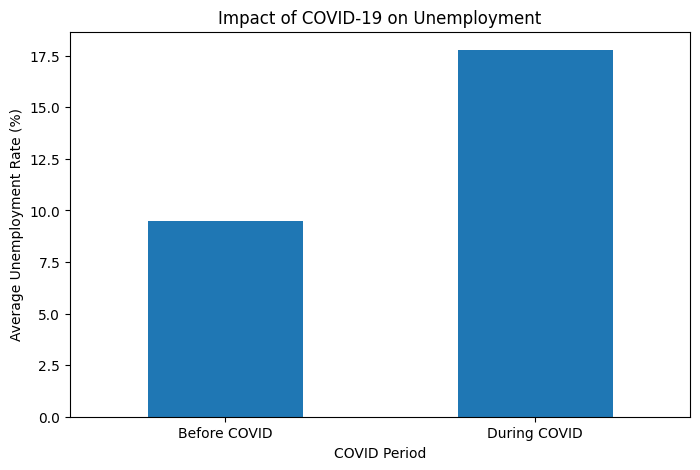

In [25]:
plt.figure(figsize=(8,5))

covid_data.plot(kind='bar')

plt.title("Impact of COVID-19 on Unemployment")
plt.xlabel("COVID Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [26]:
df['Month'] = df['Date'].dt.month

seasonal_data = df.groupby('Month')[
    'Estimated Unemployment Rate (%)'
].mean()

print(seasonal_data)

Month
1      9.950755
2      9.964717
3     10.700577
4     23.641569
5     16.646190
6     10.553462
7      9.033889
8      9.637925
9      9.051731
10     9.900909
11     9.868364
12     9.497358
Name: Estimated Unemployment Rate (%), dtype: float64


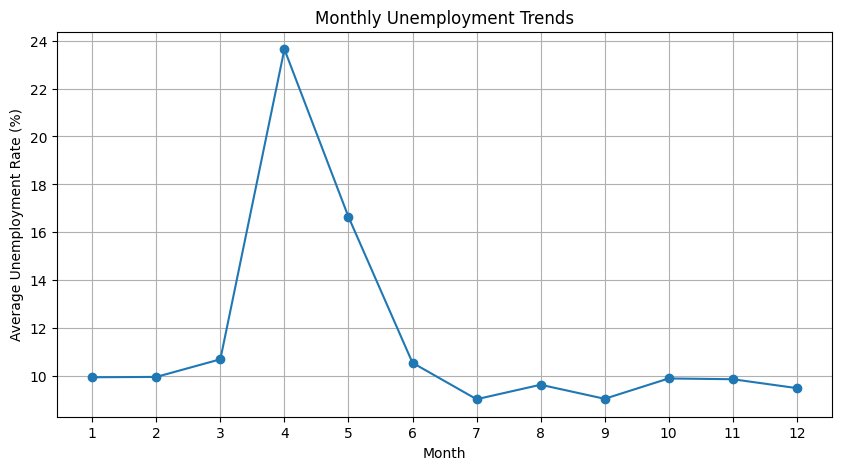

In [27]:
plt.figure(figsize=(10,5))

seasonal_data.plot(kind='line', marker='o')

plt.title("Monthly Unemployment Trends")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(range(1,13))
plt.grid(True)

plt.show()

In [28]:
print("FINAL PROJECT INSIGHTS")

print("\n1. Average Unemployment Rate:")
print(df['Estimated Unemployment Rate (%)'].mean())

print("\n2. Highest Unemployment State:")
print(region_data.idxmax())

print("\n3. Lowest Unemployment State:")
print(region_data.idxmin())

print("\n4. Before and During COVID:")
print(covid_data)

print("\n5. Rural and Urban Unemployment:")
print(area_data)

print("\n6. Monthly Unemployment Trends:")
print(seasonal_data)

FINAL PROJECT INSIGHTS

1. Average Unemployment Rate:
11.787945945945946

2. Highest Unemployment State:
Tripura

3. Lowest Unemployment State:
Meghalaya

4. Before and During COVID:
COVID Period
Before COVID     9.509534
During COVID    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64

5. Rural and Urban Unemployment:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

6. Monthly Unemployment Trends:
Month
1      9.950755
2      9.964717
3     10.700577
4     23.641569
5     16.646190
6     10.553462
7      9.033889
8      9.637925
9      9.051731
10     9.900909
11     9.868364
12     9.497358
Name: Estimated Unemployment Rate (%), dtype: float64


In [29]:
print("POLICY RECOMMENDATIONS")

print("1. Government should create more job opportunities.")

print("2. Provide skill development programs.")

print("3. Support small businesses and industries.")

print("4. Improve rural employment opportunities.")

print("5. Provide financial support during economic crises.")

POLICY RECOMMENDATIONS
1. Government should create more job opportunities.
2. Provide skill development programs.
3. Support small businesses and industries.
4. Improve rural employment opportunities.
5. Provide financial support during economic crises.


In [30]:
print("PROJECT CONCLUSION")

print("""
Unemployment analysis helps us understand
employment conditions in India.

The analysis identifies differences between
states, rural and urban areas.

COVID-19 had a major impact on employment.

Data visualization helps identify unemployment
patterns and trends.

Government should focus on job creation,
skill development and economic support.
""")

PROJECT CONCLUSION

Unemployment analysis helps us understand
employment conditions in India.

The analysis identifies differences between
states, rural and urban areas.

COVID-19 had a major impact on employment.

Data visualization helps identify unemployment
patterns and trends.

Government should focus on job creation,
skill development and economic support.

